# Simulations: White Noise

This notebook runs a Monte Carlo simulation on a pure Gaussian White Noise process:
$$y_t = \varepsilon_t, \quad \varepsilon_t \overset{\text{iid}}{\sim} \mathcal{N}(0, \sigma^2)$$

### Experimental Design
1. **Baseline Mean**: $\hat{y}_t = \bar{y}_{\text{train}}$ (theoretically optimal predictor for zero-autocorrelation stationary noise).
2. **ARMA(1,1)**: over-parameterized linear model with constant, enforcing stationarity and invertibility, evaluating parameter redundancy/cancellation ($\phi_1 \approx -\theta_1$).
3. **Random Forest (1 lag)**: non-linear model with $X_t = [y_{t-1}]$, providing an exact symmetric autoregressive counterpart to AR(1).
4. **Random Forest (4 lags)**: non-linear model with $X_t = [y_{t-1}, y_{t-2}, y_{t-7}, y_{t-14}]$ matching the lag structure used in the Careggi real data project, testing whether expanded feature space induces increased spurious fitting on noise.

## 1. Setup and Parameters

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Universal modular simulation engine and DGPs
from src.simulations import (
    generate_white_noise,
    model_mean,
    model_arima,
    model_rf_levels,
    run_simulation,
)
from src.ML_models import direct_lags

FIG_DIR = Path("figures/simulations")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("../Results/Simulations")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Simulation parameters calibrated to Careggi dataset dimensions
N_SAMPLES = 2542
N_TEST = 364
N_SIM = 500
SIGMA = 1.0
BASE_SEED = 42


## 2. Monte Carlo Simulation Execution

In [2]:
print(f"Executing {N_SIM} Monte Carlo replications (T={N_SAMPLES}, Test={N_TEST}) with canonical invertibility...")

models_wn = {
    "mean": model_mean(),
    "arma11": model_arima(
        order=(1, 0, 1),
        trend="c",
        enforce_stationarity=True,
        enforce_invertibility=True,
    ),
    "rf_1lag": model_rf_levels(lags=[1], n_estimators=100),
    "rf_4lags": model_rf_levels(lags=direct_lags(1), n_estimators=100),
}

df_results = run_simulation(
    dgp_fn=generate_white_noise,
    models=models_wn,
    n_sim=N_SIM,
    n_samples=N_SAMPLES,
    n_test=N_TEST,
    sigma=SIGMA,
    base_seed=BASE_SEED,
    n_jobs=-1,
)

csv_path = RESULTS_DIR / "wn_results_500.csv"
df_results.to_csv(csv_path, index=False)
print(f"Replication results successfully saved to: {csv_path}")


Executing 500 Monte Carlo replications (T=2542, Test=364) with canonical invertibility...


Replication results successfully saved to: ../Results/Simulations/wn_results_500.csv


## 3. Summary Statistics and Model Comparison

In [3]:
metrics_cols = {
    "Baseline Mean": ("rmse_mean", "mae_mean"),
    "ARMA(1,1)": ("rmse_arma11", "mae_arma11"),
    "RF (1 lag)": ("rmse_rf_1lag", "mae_rf_1lag"),
    "RF (4 lags)": ("rmse_rf_4lags", "mae_rf_4lags"),
}

# 1. Performance Summary Table
summary_rows = []
for model_name, (r_col, m_col) in metrics_cols.items():
    summary_rows.append({
        "Model": model_name,
        "RMSE Mean": df_results[r_col].mean(),
        "RMSE Std": df_results[r_col].std(),
        "RMSE Median": df_results[r_col].median(),
        "MAE Mean": df_results[m_col].mean(),
        "MAE Std": df_results[m_col].std(),
        "MAE Median": df_results[m_col].median(),
    })

df_summary = pd.DataFrame(summary_rows).set_index("Model")
print("=== Performance Summary across 500 White Noise Replications ===")
display(df_summary.round(4))

# Win rates
win_rf1 = (df_results["rmse_arma11"] < df_results["rmse_rf_1lag"]).mean() * 100
win_rf4 = (df_results["rmse_arma11"] < df_results["rmse_rf_4lags"]).mean() * 100
print(f"\nWin Rate (RMSE): ARMA(1,1) beats RF (1 lag)  in {win_rf1:.1f}% of replications.")
print(f"Win Rate (RMSE): ARMA(1,1) beats RF (4 lags) in {win_rf4:.1f}% of replications.")

# 2. ARMA(1,1) Parameter Estimates and Cancellation Table
df_results["phi_plus_theta"] = df_results["phi_1"] + df_results["theta_1"]
params_df = df_results[["phi_1", "theta_1", "phi_plus_theta", "intercept"]].describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
]
params_df.index = ["phi_1 (AR)", "theta_1 (MA)", "phi_1 + theta_1 (Sum)", "c (Constant)"]
print("\n=== ARMA(1,1) Estimated Parameters & Cancellation Analysis ===")
display(params_df.round(4))

# Test if sum is statistically indistinguishable from 0
t_stat, p_val = stats.ttest_1samp(df_results["phi_plus_theta"].dropna(), 0.0)
print(f"Hypothesis Test H0: (phi_1 + theta_1) == 0 -> t-statistic = {t_stat:.3f}, p-value = {p_val:.4f}")

=== Performance Summary across 500 White Noise Replications ===


,RMSE Mean,RMSE Std,RMSE Median,MAE Mean,MAE Std,MAE Median
Model,,,,,,
Baseline Mean,1.0003,0.0366,0.9989,0.7989,0.0318,0.7978
"ARMA(1,1)",1.0008,0.0366,0.9991,0.7994,0.0318,0.7976
RF (1 lag),1.2102,0.0460,1.2081,0.9667,0.0394,0.9637
RF (4 lags),1.0395,0.0370,1.0391,0.8304,0.0319,0.8291



Win Rate (RMSE): ARMA(1,1) beats RF (1 lag)  in 100.0% of replications.
Win Rate (RMSE): ARMA(1,1) beats RF (4 lags) in 99.8% of replications.

=== ARMA(1,1) Estimated Parameters & Cancellation Analysis ===


,mean,std,min,25%,50%,75%,max
phi_1 (AR),0.0270,0.5471,-0.9983,-0.3998,0.0010,0.4477,0.9972
theta_1 (MA),-0.0268,0.5511,-0.9979,-0.4506,-0.0013,0.4001,0.9999
phi_1 + theta_1 (Sum),0.0002,0.0227,-0.0571,-0.0176,0.0008,0.0171,0.0665
c (Constant),-0.0001,0.0251,-0.0971,-0.0106,0.0001,0.0113,0.1513


Hypothesis Test H0: (phi_1 + theta_1) == 0 -> t-statistic = 0.176, p-value = 0.8602


## 4. Visualizations: Model Comparison & ARMA Parameter Cancellation

We generate two dedicated, publication-quality figures:
1. **Model Forecast Accuracy Comparison (`wn_rmse_distribution.png`)**: A focused RMSE boxplot comparing the baseline mean, linear ARMA(1,1), and Random Forest (1 lag and 4 lags) against the theoretical noise floor $\sigma=1.0$.
2. **ARMA(1,1) Parameter Cancellation (`wn_arma_cancellation.png`)**: Scatter plot of $\hat{\phi}_1$ versus $-\hat{\theta}_1$ across all 500 replications demonstrating exact root redundancy along the theoretical diagonal.

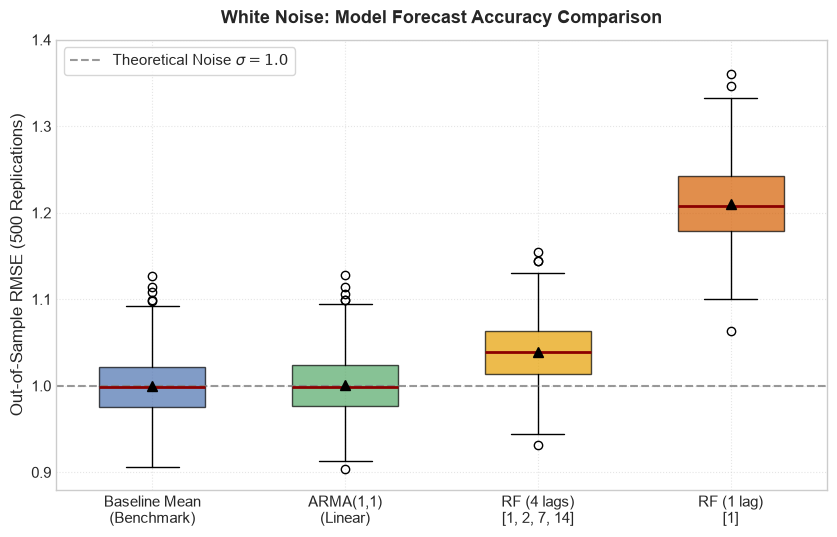

Saved: figures/simulations/wn_rmse_distribution.png


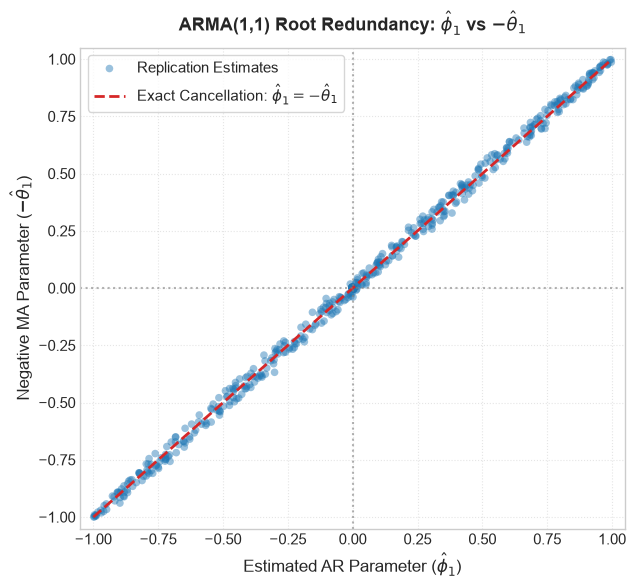

Saved: figures/simulations/wn_arma_cancellation.png


In [4]:
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "figure.titlesize": 14,
    "grid.alpha": 0.5,
    "grid.linestyle": ":",
})

# 1. Figure 1: WN RMSE Distribution (Clean Boxplot)
fig1, ax1 = plt.subplots(figsize=(8.5, 5.5))
models_wn = ["rmse_mean", "rmse_arma11", "rmse_rf_4lags", "rmse_rf_1lag"]
labels_wn = ["Baseline Mean\n(Benchmark)", "ARMA(1,1)\n(Linear)", "RF (4 lags)\n[1, 2, 7, 14]", "RF (1 lag)\n[1]"]
colors_wn = ["#4C72B0", "#55A868", "#E69F00", "#D55E00"]

data_wn = [df_results[c].dropna() for c in models_wn]
bp = ax1.boxplot(
    data_wn,
    patch_artist=True,
    tick_labels=labels_wn,
    showmeans=True,
    meanprops=dict(marker="^", markerfacecolor="black", markeredgecolor="black", markersize=7),
    medianprops=dict(color="darkred", linewidth=2),
    widths=0.55,
)

for patch, color in zip(bp["boxes"], colors_wn):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor("black")

ax1.axhline(1.0, color="gray", linestyle="--", linewidth=1.5, alpha=0.8, label=r"Theoretical Noise $\sigma = 1.0$")
ax1.set_ylabel("Out-of-Sample RMSE (500 Replications)")
ax1.set_title("White Noise: Model Forecast Accuracy Comparison", pad=12)
ax1.set_ylim(0.88, 1.40)
ax1.legend(loc="upper left", frameon=True)

plt.tight_layout()
fig1_path = FIG_DIR / "wn_rmse_distribution.png"
fig1.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved: {fig1_path}")

# 2. Figure 2: WN ARMA(1,1) Parameter Cancellation
fig2, ax2 = plt.subplots(figsize=(6.5, 6))
phi_wn = df_results["phi_1"].dropna()
theta_wn = df_results["theta_1"].dropna()

ax2.scatter(phi_wn, -theta_wn, alpha=0.45, color="#1f77b4", edgecolors="none", s=30, label="Replication Estimates")
diag = np.linspace(-1, 1, 100)
ax2.plot(diag, diag, color="#d62728", linestyle="--", linewidth=2, label=r"Exact Cancellation: $\hat{\phi}_1 = -\hat{\theta}_1$")
ax2.axhline(0, color="gray", linestyle=":", alpha=0.6)
ax2.axvline(0, color="gray", linestyle=":", alpha=0.6)

ax2.set_xlim(-1.05, 1.05)
ax2.set_ylim(-1.05, 1.05)
ax2.set_xlabel(r"Estimated AR Parameter ($\hat{\phi}_1$)")
ax2.set_ylabel(r"Negative MA Parameter ($-\hat{\theta}_1$)")
ax2.set_title(r"ARMA(1,1) Root Redundancy: $\hat{\phi}_1$ vs $-\hat{\theta}_1$", pad=12)
ax2.legend(loc="upper left", frameon=True)

plt.tight_layout()
fig2_path = FIG_DIR / "wn_arma_cancellation.png"
fig2.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved: {fig2_path}")

In [ ]:
# Nuova figura: RMSE e Penalty appaiata
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# Left panel: RMSE
models_rmse = ["rmse_mean", "rmse_arma11", "rmse_rf_4lags", "rmse_rf_1lag"]
labels_rmse = ["Baseline Mean\n(Benchmark)", "ARMA(1,1)\n(Linear)", "RF (4 lags)\n[1, 2, 7, 14]", "RF (1 lag)\n[1]"]
colors = ["#4C72B0", "#55A868", "#E69F00", "#D55E00"]

data_rmse = [df_results[c].dropna() for c in models_rmse]
bplot1 = ax1.boxplot(data_rmse, patch_artist=True, tick_labels=labels_rmse, showmeans=True, meanline=True)
for patch, color in zip(bplot1['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax1.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label=r'Theoretical $\sigma = 1$')
ax1.set_ylabel("RMSE")
ax1.legend(loc="upper left")

# Right panel: Penalty
models_pen = ["rmse_arma11", "rmse_rf_4lags", "rmse_rf_1lag"]
labels_pen = ["ARMA(1,1)", "RF (4 lags)", "RF (1 lag)"]
colors_pen = ["#55A868", "#E69F00", "#D55E00"]
penalties = [100 * (df_results[c] / df_results["rmse_mean"] - 1).dropna() for c in models_pen]

bplot2 = ax2.boxplot(penalties, patch_artist=True, tick_labels=labels_pen, showmeans=True, meanline=True)
for patch, color in zip(bplot2['boxes'], colors_pen):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax2.axhline(0.0, color='black', linestyle='--', linewidth=1.5)
ax2.set_ylabel("Penalty vs Baseline Mean (%)")

plt.tight_layout()
fig_path = FIG_DIR / "wn_rmse_penalty.png"
fig.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved: {fig_path}")
